# CRP II: SD 1.5 inpainting attack + ArcFace evaluation (batch, reads `cloak_pgd` output)

For every image, we run three branches through the same attack:

| branch | input | purpose |
|---|---|---|
| `clean` | `clean.png` | uncloaked control: what the attacker gets with no protection |
| `cloak` | `cloak_eps<E>.png` | PGD cloak, for each ε |
| `random` | `random_eps<E>.png` | random ±ε noise, same budget: shows whether the effect comes from the adversarial direction |

Each input is inpainted with Stable Diffusion 1.5: The face is encoded and decoded through VAE→diffusion→VAE result, while other parts (clothes, background) are regenerated with the same mask, prompts and seeds for every branch.

**Note:**
1. **Mask:** Use a mask that can cover the face. mouth sits around 60%. We use *MediaPipe Face Landmarker `FACE_OVAL` polygon* (36 landmarks, forehead to chin) computed from `clean.png`, with *optional dilation* (`FACE_DILATE_PX`). Each mask is computed once per image and reused for every branch, ε, prompt and seed.
2. **Face evaluation with [UniFace](https://github.com/yakhyo/uniface) (`uniface[gpu]`):** RetinaFace detection gives 5-point landmarks, ArcFace produces an L2-normalized 512-d embedding, and we take the cosine similarity with the clean source face. If no face is detected, the row is recorded as `face_found=False`, which counts as *protected*.
3. **Batch and resumable:** loops over images × branches × ε × prompts × seeds. Outputs that already exist are skipped, so a Colab disconnect doesn't lose work if you save to Drive.
4. **Threshold τ** from genuine vs imposter pairs (compare 2 different people), a protection-success rate per condition, plots and image grids.

**Before running:** `Runtime → Change runtime type → T4 GPU`.

## 1. Install

In [ ]:
# A CPU-only onnxruntime would shadow the GPU build that uniface[gpu] installs, so remove it first.
!pip uninstall -y -q onnxruntime
!pip install -q -U diffusers transformers accelerate mediapipe "uniface[gpu]"

In [ ]:
# import torch BEFORE onnxruntime so its CUDA/cuDNN libraries are loaded
import os, re, json, time, math, shutil, zipfile, itertools, urllib.request
import numpy as np
import pandas as pd
import torch
import cv2
from PIL import Image
import matplotlib.pyplot as plt

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# onnxruntime-gpu ≥ 1.21, reuse the CUDA/cuDNN that ships with torc
import onnxruntime as ort
try:
    ort.preload_dlls()
except Exception:
    pass

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"device={device} | torch={torch.__version__} | onnxruntime providers={ort.get_available_providers()}")
if "CUDAExecutionProvider" not in ort.get_available_providers():
    print("NOTE: UniFace will run on CPU. That's fine (≈0.1–0.3 s per image), just slower.")

device=cuda | torch=2.14.1+cu130 | onnxruntime providers=['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']


## 2. Configuration
`QUICK_TEST = True` runs a smoke test: 2 images, the largest ε only, 1 prompt, 1 seed.

In [ ]:
# Cloak notebook output dir, include manifest.csv + images/
CLOAK_OUT_DIR = "/content/drive/MyDrive/CRPII/cloak_out"
SAVE_TO_DRIVE = True
OUT_DIR = "/content/drive/MyDrive/CRPII/inpaint_out" if SAVE_TO_DRIVE else "/content/inpaint_out"

# Configuration
EPS_TO_USE     = None          # pertubation budget, None = every ε in manifest.csv
INCLUDE_RANDOM = True          # evaluate a "random noise" control branch alongside clean and cloake
SOURCES        = ["ffhq", "selfie"]
MAX_IMAGES     = None

# ===== Face mask (MediaPipe Face Landmarker, FACE_OVAL) =====
FACE_DILATE_PX = 0             # grow the kept face region outward by N pixels (0 = exact oval; try 8–15 to keep the jaw edge)
MIN_FACE_CONF  = 0.3
LANDMARKER_URL = ("https://storage.googleapis.com/mediapipe-models/face_landmarker/"
                  "face_landmarker/float16/1/face_landmarker.task")

# ===== Inpainting attack (Stable Diffusion 1.5) =====
MODEL_ID        = "stable-diffusion-v1-5/stable-diffusion-inpainting"
PROMPTS = [
    "a person standing outdoors in a park, natural lighting, photorealistic",
    "a person in a police station, wearing an orange prison jumpsuit, photorealistic",
    "a person at a nightclub at night, flash photography, photorealistic",
]
NEGATIVE_PROMPT = "blurry, deformed, extra limbs, bad anatomy"
SEEDS           = [0, 1, 2]
NUM_STEPS       = 30
GUIDANCE        = 7.5
KEEP_SAFETY_CHECKER = True     # flagged (blacked-out) outputs are recorded and EXCLUDED from metrics,
                               # so a black image is never mistaken for "protected"

# ===== Face evaluation (UniFace) =====
DETECTOR    = "retinaface_r50"     # RetinaFace weights: retinaface_mnet_v2 (fast) … retinaface_r50 (most accurate)
RECOGNIZER  = "arcface_resnet"     # ArcFace weights: arcface_resnet (stronger) or arcface_mnet
DET_CONF    = 0.5
TAU_RULE    = "far1"               # "far1" = τ at 1% false-accept rate on impostor pairs; "eer" = equal error rate

QUICK_TEST = False

if QUICK_TEST:
    MAX_IMAGES, PROMPTS, SEEDS = 2, PROMPTS[:1], SEEDS[:1]

## 3. Load the cloak output

In [ ]:
if IN_COLAB and (SAVE_TO_DRIVE or CLOAK_OUT_DIR.startswith("/content/drive")):
    from google.colab import drive
    drive.mount("/content/drive")
if not IN_COLAB and OUT_DIR.startswith("/content"):
    OUT_DIR = os.path.abspath("inpaint_out")

def find_manifest(root):
    for dirpath, _, files in os.walk(root):
        if "manifest.csv" in files:
            return dirpath
    return None

if not os.path.exists(os.path.join(CLOAK_OUT_DIR, "manifest.csv")):
    if IN_COLAB:
        from google.colab import files
        print(f"{CLOAK_OUT_DIR}/manifest.csv not found → upload the cloak_out.zip made by crpII_cloak_pgd.ipynb")
        up = files.upload()
        os.makedirs(CLOAK_OUT_DIR, exist_ok=True)
        for name, data in up.items():
            zp = os.path.join("/content", name)
            with open(zp, "wb") as f:
                f.write(data)
            with zipfile.ZipFile(zp) as z:
                z.extractall(CLOAK_OUT_DIR)
    found = find_manifest(CLOAK_OUT_DIR) if os.path.exists(CLOAK_OUT_DIR) else None
    assert found, f"No manifest.csv under {CLOAK_OUT_DIR}"
    CLOAK_OUT_DIR = found        # handles zips that contain an extra top-level folder

man = pd.read_csv(os.path.join(CLOAK_OUT_DIR, "manifest.csv"))
print(f"Cloak manifest: {len(man)} rows, {man.img_id.nunique()} images, ε = {sorted(man.eps.unique())}")

# ---- build the list of inputs to attack: one row per (image, branch, ε) ----
man = man[man.source.isin(SOURCES)]
if EPS_TO_USE is not None:
    man = man[man.eps.isin(EPS_TO_USE)]
img_ids = sorted(man.img_id.unique())
if MAX_IMAGES:
    # keep a mix of sources: alternate ffhq / selfie when both exist
    by_src = {s: sorted(man[man.source == s].img_id.unique()) for s in SOURCES}
    mixed = [i for pair in itertools.zip_longest(*by_src.values()) for i in pair if i]
    img_ids = mixed[:MAX_IMAGES]
man = man[man.img_id.isin(img_ids)]
if QUICK_TEST:
    man = man[man.eps == man.eps.max()]

variants = []
for img_id, g in man.groupby("img_id"):
    r0 = g.iloc[0]
    variants.append(dict(img_id=img_id, source=r0.source, branch="clean", eps=0, input_path=r0.clean_path))
    for _, r in g.iterrows():
        variants.append(dict(img_id=img_id, source=r.source, branch="cloak", eps=int(r.eps), input_path=r.cloak_path))
        if INCLUDE_RANDOM and isinstance(r.get("random_path", None), str):
            variants.append(dict(img_id=img_id, source=r.source, branch="random", eps=int(r.eps), input_path=r.random_path))
variants = pd.DataFrame(variants)
clean_of = {v.img_id: v.input_path for v in variants[variants.branch == "clean"].itertuples()}

for sub in ["masks", "outputs", "figures"]:
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)
n_gen = len(variants) * len(PROMPTS) * len(SEEDS)
print(f"{len(img_ids)} images → {len(variants)} inputs × {len(PROMPTS)} prompts × {len(SEEDS)} seeds "
      f"= {n_gen} inpaintings (≈{n_gen * 3.5 / 3600:.1f} h on a T4 at {NUM_STEPS} steps, rough guess)")
print(variants.groupby(["branch", "eps"]).size().rename("n_inputs").to_string())
print("Writing to", OUT_DIR)

Mounted at /content/drive
Cloak manifest: 2 rows, 2 images, ε = [np.int64(16)]
2 images → 6 inputs × 3 prompts × 3 seeds = 54 inpaintings (≈0.1 h on a T4 at 30 steps, rough guess)
branch  eps
clean   0      2
cloak   16     2
random  16     2
Writing to /content/drive/MyDrive/CRPII/inpaint_out


## 4. Face masks: MediaPipe `FACE_OVAL` (+ optional dilation)
Masks are computed **once, from `clean.png`**, and reused for every branch, so the cloak or the noise can't move the mask. Diffusers convention: **white = regenerate, black = keep**. Two files are saved per image:
* `masks/<id>_face.png`: white = kept face
* `masks/<id>_inpaint.png`: the inverse, passed to the pipeline

If no face is found, the image is skipped and listed.

In [ ]:
from mediapipe.tasks.python import vision as mp_vision
from mediapipe.tasks.python import BaseOptions
import mediapipe as mp

LANDMARKER_PATH = os.path.join(OUT_DIR, "face_landmarker.task")
if not os.path.exists(LANDMARKER_PATH):
    urllib.request.urlretrieve(LANDMARKER_URL, LANDMARKER_PATH)
landmarker = mp_vision.FaceLandmarker.create_from_options(mp_vision.FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=LANDMARKER_PATH), num_faces=1,
    min_face_detection_confidence=MIN_FACE_CONF, min_face_presence_confidence=MIN_FACE_CONF))
print("MediaPipe Face Landmarker ready.")

Masks ready for 2 images (dilation = 0px).


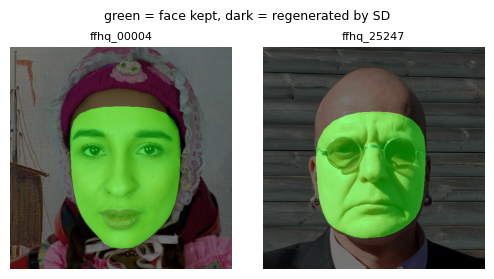

In [ ]:
# Face-oval landmark indices of the 468/478-point MediaPipe face mesh, in polygon order (forehead → right cheek → chin → left cheek)
FACE_OVAL = [10, 338, 297, 332, 284, 251, 389, 356, 454, 323, 361, 288, 397, 365, 379, 378, 400, 377,
             152, 148, 176, 149, 150, 136, 172, 58, 132, 93, 234, 127, 162, 21, 54, 103, 67, 109]

def face_oval_mask(rgb, dilate_px=FACE_DILATE_PX):
    # rgb: HxWx3 uint8. Returns uint8 mask (255 = face to keep) or None if no face.
    h, w = rgb.shape[:2]
    res = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb)))
    if not res.face_landmarks:
        return None
    lm = res.face_landmarks[0]
    poly = np.array([[lm[i].x * w, lm[i].y * h] for i in FACE_OVAL], dtype=np.float32)
    poly = np.clip(poly.round(), 0, [w - 1, h - 1]).astype(np.int32)
    mask = np.zeros((h, w), np.uint8)
    cv2.fillPoly(mask, [poly], 255)
    if dilate_px > 0:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * dilate_px + 1, 2 * dilate_px + 1))
        mask = cv2.dilate(mask, k)
    return mask

mask_ok, mask_failed = {}, []
for img_id in img_ids:
    face_p = os.path.join(OUT_DIR, "masks", f"{img_id}_face.png")
    inp_p = os.path.join(OUT_DIR, "masks", f"{img_id}_inpaint.png")
    if not os.path.exists(inp_p):
        rgb = np.asarray(Image.open(os.path.join(CLOAK_OUT_DIR, clean_of[img_id])).convert("RGB"))
        m = face_oval_mask(rgb)
        if m is None:
            mask_failed.append(img_id)
            continue
        Image.fromarray(m).save(face_p)
        Image.fromarray(255 - m).save(inp_p)
    mask_ok[img_id] = inp_p

if mask_failed:
    print(f"⚠ No face found by MediaPipe in {len(mask_failed)} image(s), skipped: {mask_failed}")
variants = variants[variants.img_id.isin(mask_ok)].reset_index(drop=True)
img_ids = [i for i in img_ids if i in mask_ok]
print(f"Masks ready for {len(mask_ok)} images (dilation = {FACE_DILATE_PX}px).")

# preview: kept face region tinted green
show = img_ids[:6]
fig, axes = plt.subplots(1, len(show), figsize=(2.6 * len(show), 2.8), squeeze=False)
for ax, i in zip(axes[0], show):
    rgb = np.asarray(Image.open(os.path.join(CLOAK_OUT_DIR, clean_of[i])).convert("RGB")).astype(float)
    keep = np.asarray(Image.open(os.path.join(OUT_DIR, "masks", f"{i}_face.png")))[..., None] > 127
    tint = np.where(keep, 0.55 * rgb + 0.45 * np.array([0, 255, 0]), 0.45 * rgb)
    ax.imshow(tint.astype(np.uint8)); ax.set_title(i, fontsize=8); ax.axis("off")
plt.suptitle("green = face kept, dark = regenerated by SD", fontsize=9); plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "figures", "mask_preview.png"), dpi=110, bbox_inches="tight"); plt.show()

## 5. Load SD 1.5 inpainting

Hugging Face didn't find the weights formatted in the modern .safetensors format, so it fell back to loading them from the standard, picklable .bin (PyTorch) format weights.

In [ ]:
from diffusers import StableDiffusionInpaintPipeline

extra = {} if KEEP_SAFETY_CHECKER else dict(safety_checker=None, requires_safety_checker=False)
pipe = StableDiffusionInpaintPipeline.from_pretrained(
    MODEL_ID, torch_dtype=torch.float16 if device == "cuda" else torch.float32, **extra).to(device)
pipe.set_progress_bar_config(disable=True)
print("Inpainting pipeline loaded:", MODEL_ID)

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Inpainting pipeline loaded: stable-diffusion-v1-5/stable-diffusion-inpainting


## 6. Run the attack
For each input × prompt, all missing seeds are generated in **one batched call**, one `torch.Generator` per seed. Seed *s* therefore gives the same image whether it runs alone or in a batch, and it is identical across the clean, cloak and random branches. Outputs go to `outputs/<img_id>/<branch>[_eps<E>]/p<prompt>_s<seed>.png`, and `generations.csv` keeps one row per output. Re-running skips anything already on disk.

In [ ]:
GEN_CSV = os.path.join(OUT_DIR, "generations.csv")
gen_rows = pd.read_csv(GEN_CSV).to_dict("records") if os.path.exists(GEN_CSV) else []
have = {r["out_path"] for r in gen_rows if os.path.exists(os.path.join(OUT_DIR, r["out_path"]))}
gen_rows = [r for r in gen_rows if r["out_path"] in have]

def out_rel(v, pid, seed):
    tag = v.branch if v.branch == "clean" else f"{v.branch}_eps{v.eps}"
    return os.path.join("outputs", v.img_id, tag, f"p{pid}_s{seed}.png")

jobs = []
for v in variants.itertuples():
    for pid in range(len(PROMPTS)):
        missing = [s for s in SEEDS if out_rel(v, pid, s) not in have]
        if missing:
            jobs.append((v, pid, missing))
todo = sum(len(j[2]) for j in jobs)
print(f"{len(have)} outputs already done, {todo} to generate.")

t0, done_now = time.time(), 0
for k, (v, pid, seeds) in enumerate(jobs):
    image = Image.open(os.path.join(CLOAK_OUT_DIR, v.input_path)).convert("RGB")
    mask = Image.open(mask_ok[v.img_id]).convert("L")
    W, H = image.size
    out = pipe(prompt=PROMPTS[pid], negative_prompt=NEGATIVE_PROMPT, image=image, mask_image=mask,
               height=H, width=W, num_inference_steps=NUM_STEPS, guidance_scale=GUIDANCE,
               num_images_per_prompt=len(seeds),
               generator=[torch.Generator(device=device).manual_seed(s) for s in seeds])
    nsfw = out.nsfw_content_detected or [False] * len(seeds)
    for img, s, flag in zip(out.images, seeds, nsfw):
        rel = out_rel(v, pid, s)
        os.makedirs(os.path.dirname(os.path.join(OUT_DIR, rel)), exist_ok=True)
        img.save(os.path.join(OUT_DIR, rel))
        gen_rows.append(dict(img_id=v.img_id, source=v.source, branch=v.branch, eps=v.eps, breaker="none",
                             prompt_id=pid, seed=s, input_path=v.input_path, out_path=rel, nsfw=bool(flag)))
    done_now += len(seeds)
    if (k + 1) % 5 == 0 or k == len(jobs) - 1:
        pd.DataFrame(gen_rows).to_csv(GEN_CSV, index=False)
        rate = (time.time() - t0) / done_now
        print(f"[{k+1}/{len(jobs)}] {v.img_id} {v.branch} ε={v.eps} p{pid} | {rate:.1f}s/img | "
              f"ETA {(todo - done_now) * rate / 60:.1f} min")
pd.DataFrame(gen_rows).to_csv(GEN_CSV, index=False)
gens = pd.read_csv(GEN_CSV)
print(f"Done: {len(gens)} outputs ({gens.nsfw.sum()} flagged by the safety checker).")

0 outputs already done, 54 to generate.


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


[5/18] ffhq_00004 cloak ε=16 p1 | 4.7s/img | ETA 3.1 min


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


[10/18] ffhq_25247 clean ε=0 p0 | 4.9s/img | ETA 1.9 min


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


[15/18] ffhq_25247 cloak ε=16 p2 | 4.9s/img | ETA 0.7 min
[18/18] ffhq_25247 random ε=16 p2 | 4.9s/img | ETA 0.0 min
Done: 54 outputs (4 flagged by the safety checker).


## 7. Face evaluation with UniFace (RetinaFace + ArcFace)
* **Source embedding:** from `clean.png`.
* **For each output:** detect faces with RetinaFace. If there are several, take the one that **overlaps the source face box most** (IoU), so a background face SD invented isn't picked. Then embed the chosen face with ArcFace using its 5 landmarks. `sim` is the cosine similarity with the source embedding.
* `sim_input` is the similarity between the source and the *input* to the attack (cloak or noise image). It shows whether the cloak alone already fools ArcFace before any editing.
* **No face detected** → `face_found=False`, `sim=NaN`, counted as **protected**.

In [ ]:
from uniface import RetinaFace, ArcFace
from uniface.constants import RetinaFaceWeights, ArcFaceWeights

detector = RetinaFace(model_name=RetinaFaceWeights(DETECTOR), confidence_threshold=DET_CONF)
recognizer = ArcFace(model_name=ArcFaceWeights(RECOGNIZER))
print("UniFace ready:", DETECTOR, "+", RECOGNIZER)



Attempt 1/3:   0%|          | 0.00/104M [00:00<?, ?B/s]

Attempt 1/3:   3%|▎         | 3.50M/104M [00:00<00:06, 16.1MB/s]

Attempt 1/3:   7%|▋         | 7.00M/104M [00:00<00:06, 15.8MB/s]

Attempt 1/3:  10%|▉         | 10.2M/104M [00:00<00:07, 12.8MB/s]

Attempt 1/3:  11%|█▏        | 11.8M/104M [00:00<00:07, 13.1MB/s]

Attempt 1/3:  13%|█▎        | 13.2M/104M [00:01<00:08, 10.8MB/s]

Attempt 1/3:  14%|█▍        | 14.8M/104M [00:01<00:08, 11.4MB/s]

Attempt 1/3:  15%|█▌        | 16.0M/104M [00:01<00:09, 9.68MB/s]

Attempt 1/3:  17%|█▋        | 17.5M/104M [00:01<00:08, 10.7MB/s]

Attempt 1/3:  18%|█▊        | 19.0M/104M [00:01<00:07, 11.5MB/s]

Attempt 1/3:  19%|█▉        | 20.2M/104M [00:02<00:11, 7.45MB/s]

Attempt 1/3:  20%|██        | 21.2M/104M [00:02<00:13, 6.39MB/s]

Attempt 1/3:  22%|██▏       | 22.5M/104M [00:02<00:11, 7.40MB/s]

Attempt 1/3:  23%|██▎       | 23.5M/104M [00:02<00:12, 6.86MB/s]

Attempt 1/3:  24%|██▍       | 25.0M/104M [00:02<00:10, 8.32MB/s]

Attempt 1/3:  25%

UniFace ready: retinaface_r50 + arcface_resnet


In [ ]:
def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1]); x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

def face_embed(path, ref_box=None):
    # Returns (embedding or None, det_conf, iou_with_ref, n_faces, bbox).
    bgr = cv2.imread(path)                                 # UniFace expects BGR
    faces = detector.detect(bgr)
    if not faces:
        return None, np.nan, np.nan, 0, None
    if ref_box is not None:
        ious = [iou(f.bbox, ref_box) for f in faces]
        j = int(np.argmax(ious)) if max(ious) > 0 else int(np.argmax([(f.bbox[2]-f.bbox[0])*(f.bbox[3]-f.bbox[1]) for f in faces]))
        ov = ious[j]
    else:
        j = int(np.argmax([(f.bbox[2]-f.bbox[0])*(f.bbox[3]-f.bbox[1]) for f in faces])); ov = np.nan
    f = faces[j]
    emb = recognizer.get_normalized_embedding(bgr, f.landmarks).ravel()
    return emb / np.linalg.norm(emb), float(f.confidence), ov, len(faces), np.asarray(f.bbox, float)

# --- source faces (clean.png) ---
src = {}
for img_id in img_ids:
    e, conf, _, n, box = face_embed(os.path.join(CLOAK_OUT_DIR, clean_of[img_id]))
    if e is None:
        print(f"⚠ UniFace found no face in clean {img_id}, so it is excluded from evaluation")
        continue
    src[img_id] = dict(emb=e, box=box)

# --- similarity of the attack INPUTS (does the cloak alone change identity?) ---
input_sim = {}
for v in variants.itertuples():
    if v.img_id in src:
        e, *_ = face_embed(os.path.join(CLOAK_OUT_DIR, v.input_path), src[v.img_id]["box"])
        input_sim[(v.img_id, v.branch, v.eps)] = float(e @ src[v.img_id]["emb"]) if e is not None else np.nan

# --- outputs (resumable) ---
RES_CSV = os.path.join(OUT_DIR, "results.csv")
res_rows = pd.read_csv(RES_CSV).to_dict("records") if os.path.exists(RES_CSV) else []
seen = {r["out_path"] for r in res_rows}
gens = pd.read_csv(os.path.join(OUT_DIR, "generations.csv"))
todo = gens[~gens.out_path.isin(seen) & gens.img_id.isin(src)]
t0 = time.time()
for n, g in enumerate(todo.itertuples(), 1):
    e, conf, ov, nf, _ = face_embed(os.path.join(OUT_DIR, g.out_path), src[g.img_id]["box"])
    res_rows.append(dict(g._asdict(), face_found=e is not None, det_conf=conf, iou=ov, n_faces=nf,
                         sim=float(e @ src[g.img_id]["emb"]) if e is not None else np.nan,
                         sim_input=input_sim.get((g.img_id, g.branch, g.eps), np.nan)))
    if n % 200 == 0:
        pd.DataFrame(res_rows).drop(columns=["Index"], errors="ignore").to_csv(RES_CSV, index=False)
        print(f"  evaluated {n}/{len(todo)} ({(time.time()-t0)/n:.2f}s/img)")
res = pd.DataFrame(res_rows).drop(columns=["Index"], errors="ignore")
res.to_csv(RES_CSV, index=False)
print(f"results.csv: {len(res)} rows | faces found in {res.face_found.mean():.1%} of outputs")

results.csv: 54 rows | faces found in 92.6% of outputs


Faces were successfully found in 50 out of 54 images. The remaining 4 images did not have faces detected because of NSFW/Safety Checker interventions

## 8. Threshold τ and protection-success rate
* **Impostor pairs:** clean source faces of *different* images. Selfie–selfie pairs are left out because several selfies may show the same person.
* **Genuine pairs:** source face vs the **clean-branch (uncloaked) edited output** of the same image, i.e. what a successful deepfake looks like to ArcFace.
* τ is set at a 1% false-accept rate on impostors (`far1`) or at the equal error rate (`eer`).
* **Protection success** = no face found, or `sim < τ`. Rows flagged by the safety checker are excluded.

With only ~35–40 sources, τ is a first estimate. The proposal's final thresholds will use the full dataset.

In [ ]:
ids = sorted(src)
imp = np.array([src[a]["emb"] @ src[b]["emb"] for a, b in itertools.combinations(ids, 2)
                if not (a.startswith("selfie_") and b.startswith("selfie_"))])
ev = res[~res.nsfw]
gen = ev[(ev.branch == "clean") & ev.face_found].sim.values

def eer_threshold(genuine, impostor):
    ts = np.unique(np.concatenate([genuine, impostor]))
    far = np.array([(impostor >= t).mean() for t in ts]); frr = np.array([(genuine < t).mean() for t in ts])
    d = np.abs(far - frr)
    ks = np.flatnonzero(d == d.min())                  # several thresholds can tie → take the middle one
    k = int(ks[len(ks) // 2])
    return float(ts[k]), float((far[k] + frr[k]) / 2)

tau_far1 = float(np.quantile(imp, 0.99)) if len(imp) else np.nan
tau_eer, eer = eer_threshold(gen, imp) if len(gen) and len(imp) else (np.nan, np.nan)
TAU = tau_far1 if TAU_RULE == "far1" else tau_eer
print(f"impostor pairs={len(imp)}, genuine (clean-branch outputs)={len(gen)}")
print(f"τ @ FAR 1% = {tau_far1:.3f} | τ @ EER = {tau_eer:.3f} (EER = {eer:.1%}) → using τ = {TAU:.3f} ({TAU_RULE})")

ev = ev.assign(protected=(~ev.face_found) | (ev.sim < TAU))
summary = (ev.groupby(["branch", "eps"])
             .agg(n=("sim", "size"), face_rate=("face_found", "mean"), mean_sim=("sim", "mean"),
                  median_sim=("sim", "median"), mean_sim_input=("sim_input", "mean"),
                  protection_rate=("protected", "mean"))
             .round(3))
summary.to_csv(os.path.join(OUT_DIR, "summary.csv"))
display(summary)

# per-source view (studio FFHQ vs in-the-wild selfies)
display(ev.groupby(["source", "branch", "eps"]).agg(n=("sim", "size"), mean_sim=("sim", "mean"),
                                                     protection_rate=("protected", "mean")).round(3))

# paired effect: same image / prompt / seed, cloak vs clean control
ctrl = ev[ev.branch == "clean"].set_index(["img_id", "prompt_id", "seed"]).sim
paired = (ev[ev.branch != "clean"].join(ctrl.rename("sim_ctrl"), on=["img_id", "prompt_id", "seed"])
            .assign(delta=lambda d: d.sim_ctrl - d.sim))
display(paired.groupby(["branch", "eps"]).delta.agg(["mean", "std", "count"]).round(3)
        .rename(columns={"mean": "mean Δsim (ctrl − branch)"}))

impostor pairs=1, genuine (clean-branch outputs)=18
τ @ FAR 1% = -0.018 | τ @ EER = 0.695 (EER = 0.0%) → using τ = -0.018 (far1)


,,n,face_rate,mean_sim,median_sim,mean_sim_input,protection_rate
branch,eps,,,,,,
clean,0,18,1.0,0.843,0.867,1.000,0.0
cloak,16,14,1.0,0.696,0.699,0.944,0.0
random,16,18,1.0,0.767,0.803,0.921,0.0


n  mean_sim  protection_rate
source branch eps                               
ffhq   clean  0    18     0.843              0.0
       cloak  16   14     0.696              0.0
       random 16   18     0.767              0.0

,,mean Δsim (ctrl − branch),std,count
branch,eps,,,
cloak,16,0.135,0.069,14
random,16,0.077,0.032,18


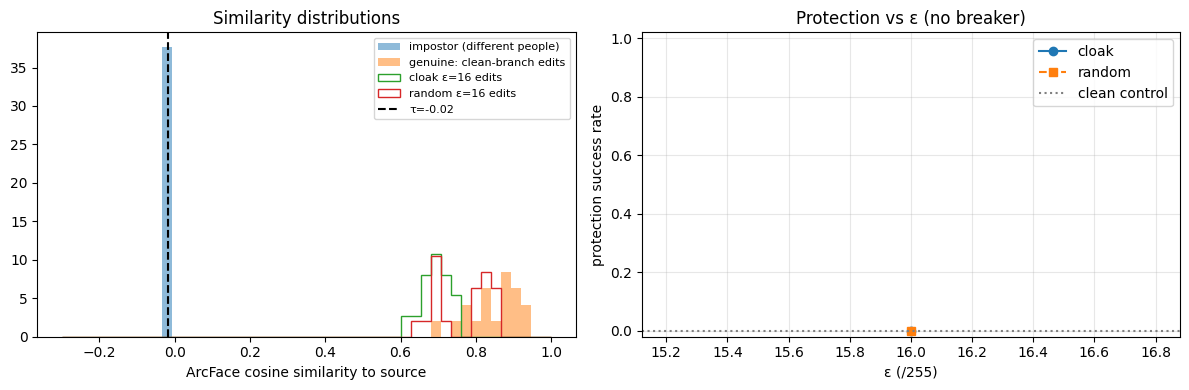

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(-0.3, 1.0, 50)
ax[0].hist(imp, bins, alpha=.5, density=True, label="impostor (different people)")
ax[0].hist(gen, bins, alpha=.5, density=True, label="genuine: clean-branch edits")
eps_max = ev.eps.max()
for b in ["cloak", "random"]:
    s = ev[(ev.branch == b) & (ev.eps == eps_max) & ev.face_found].sim
    if len(s):
        ax[0].hist(s, bins, histtype="step", lw=2, density=True, label=f"{b} ε={eps_max} edits")
ax[0].axvline(TAU, color="k", ls="--", label=f"τ={TAU:.2f}")
ax[0].set_xlabel("ArcFace cosine similarity to source"); ax[0].legend(fontsize=8); ax[0].set_title("Similarity distributions")

c = summary.reset_index()
base = c[c.branch == "clean"].protection_rate.mean() if (c.branch == "clean").any() else np.nan
for b, mk in [("cloak", "o-"), ("random", "s--")]:
    d = c[c.branch == b]
    if len(d):
        ax[1].plot(d.eps, d.protection_rate, mk, label=b)
ax[1].axhline(base, color="gray", ls=":", label="clean control")
ax[1].set_xlabel("ε (/255)"); ax[1].set_ylabel("protection success rate"); ax[1].set_ylim(-0.02, 1.02)
ax[1].set_title("Protection vs ε (no breaker)"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "figures", "similarity_and_protection.png"), dpi=120); plt.show()

Since these similarity scores are far above the strict decision boundary, not a single face was classified as protected based on the threshold.

## 9. Visual grid: source | mask | edited (clean / cloak / random)

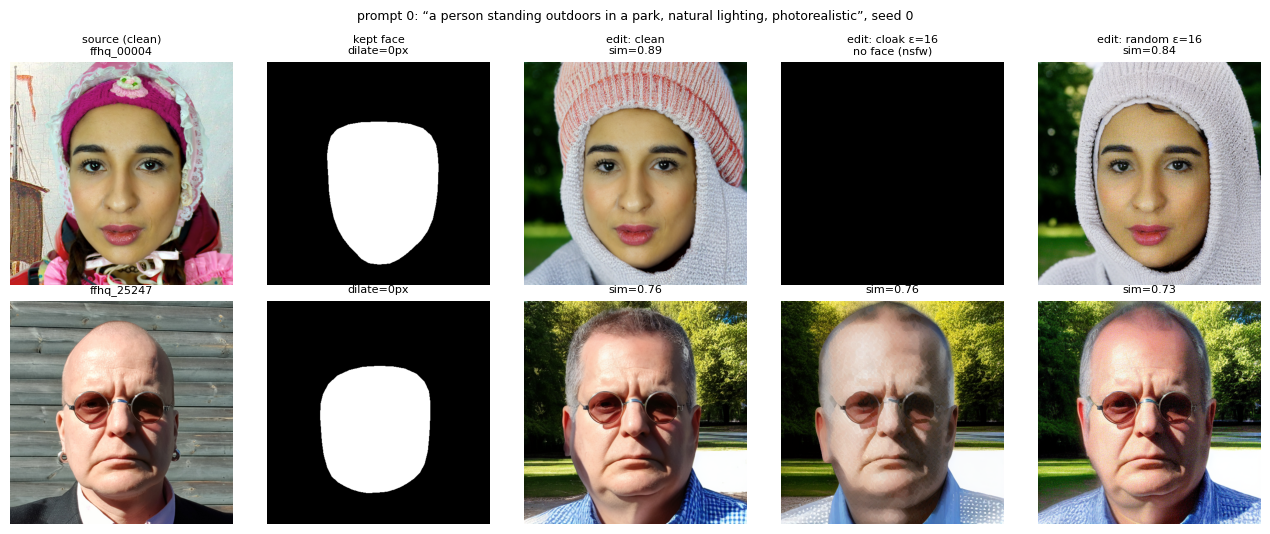

In [ ]:
N_SHOW, PID, SEED_SHOW = 4, 0, SEEDS[0]
eps_show = int(ev.eps.max())
rows_show = img_ids[:N_SHOW]
cols = ["source (clean)", "kept face", "edit: clean", f"edit: cloak ε={eps_show}", f"edit: random ε={eps_show}"]
fig, axes = plt.subplots(len(rows_show), len(cols), figsize=(2.6 * len(cols), 2.7 * len(rows_show)), squeeze=False)
for r, i in enumerate(rows_show):
    def pick(branch, eps):
        q = res[(res.img_id == i) & (res.branch == branch) & (res.eps == eps) & (res.prompt_id == PID) & (res.seed == SEED_SHOW)]
        return q.iloc[0] if len(q) else None
    panels = [(Image.open(os.path.join(CLOAK_OUT_DIR, clean_of[i])), i),
              (Image.open(os.path.join(OUT_DIR, "masks", f"{i}_face.png")), f"dilate={FACE_DILATE_PX}px")]
    for b, e in [("clean", 0), ("cloak", eps_show), ("random", eps_show)]:
        q = pick(b, e)
        if q is None:
            panels.append((None, "n/a"))
        else:
            t = "no face" if not q.face_found else f"sim={q.sim:.2f}"
            panels.append((Image.open(os.path.join(OUT_DIR, q.out_path)), t + (" (nsfw)" if q.nsfw else "")))
    for c_, (im, t) in enumerate(panels):
        a = axes[r, c_]; a.axis("off")
        if im is not None:
            a.imshow(im, cmap="gray" if c_ == 1 else None)
        a.set_title((cols[c_] + "\n" if r == 0 else "") + t, fontsize=8)
plt.suptitle(f"prompt {PID}: “{PROMPTS[PID]}”, seed {SEED_SHOW}", fontsize=9); plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "figures", f"grid_p{PID}_s{SEED_SHOW}_eps{eps_show}.png"), dpi=110, bbox_inches="tight")
plt.show()

## 10. Save / download

In [ ]:
with open(os.path.join(OUT_DIR, "config.json"), "w") as f:
    json.dump(dict(CLOAK_OUT_DIR=CLOAK_OUT_DIR, EPS_TO_USE=EPS_TO_USE, INCLUDE_RANDOM=INCLUDE_RANDOM,
                   FACE_DILATE_PX=FACE_DILATE_PX, MODEL_ID=MODEL_ID, PROMPTS=PROMPTS,
                   NEGATIVE_PROMPT=NEGATIVE_PROMPT, SEEDS=SEEDS, NUM_STEPS=NUM_STEPS, GUIDANCE=GUIDANCE,
                   KEEP_SAFETY_CHECKER=KEEP_SAFETY_CHECKER, DETECTOR=DETECTOR, RECOGNIZER=RECOGNIZER,
                   TAU_RULE=TAU_RULE, TAU=TAU, tau_far1=tau_far1, tau_eer=tau_eer), f, indent=2)
if IN_COLAB and not SAVE_TO_DRIVE:
    from google.colab import files
    zp = shutil.make_archive("/content/inpaint_out", "zip", OUT_DIR)
    files.download(zp)
else:
    print("Results are in", OUT_DIR)

Results are in /content/drive/MyDrive/CRPII/inpaint_out


### Next step: cloak breakers
`generations.csv` / `results.csv` already have a `breaker` column (`"none"` here). For the breaker stage, apply each breaker (JPEG 95/75/50, resize, blur, noise+upscale, purification) to **both** the clean and the cloak/random inputs, save them next to the originals, and add them to `variants` with `breaker=<name>`. The masks, prompts, seeds and evaluation code here are reused unchanged.